Import libraries

In [1]:
import os
import sys
import copy
import time
import importlib
import numpy as np
import pandas as pd
import tensorflow as tf
import joblib as jl
threads = 4

from tqdm.notebook import tqdm

In [2]:
import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib import ticker
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
# %matplotlib notebook

# # Use custom style
# # See: https://matplotlib.org/1.5.3/users/style_sheets.html
# style_name = 'paper_1column'
# mpl.style.use(
#     os.environ['WORKSPACE_PATH'] \
#         + '/RESEARCH/styles/matplotlib/' \
#         + style_name + '.mplstyle'
# )
# # Get colors list
# COLORS = mpl.rcParams['axes.prop_cycle'].by_key()['color']*10

In [3]:
T = 15000
frames = 100

cwd = os.getcwd()
figs = cwd + f'/figs_T{T}K'
try:
    os.mkdir(figs)
except:
    pass

Define paths

In [4]:
sts_fld = cwd + f'/../../isothermal/O3/nestedTimescales/postprocess/CG-DeepONet/src/sts_cg_park/T{T}K'
sts_file = sts_fld + '/sts/excit_diss/output_box/box.dat'
pop_file = sts_fld + '/sts/excit_diss/output_box/pop_O2.dat'
lev_file = '/home/zanardi/WORKSPACE/database/levels/O2.csv'

Manipulate energy levels

In [5]:
lev_dtb = pd.read_csv(lev_file)
lev_dtb['EVib'] = lev_dtb['EVib'] - np.amin(lev_dtb['EVib'])
lev_dtb['ERot'] = lev_dtb['ERot'] - np.amin(lev_dtb['ERot'])
lev_dtb['E'] = lev_dtb['EVib'] + lev_dtb['ERot']
lev_dtb['g'] = 3./2.*(2.*lev_dtb['jqn'] + 1.)
n_lev = len(lev_dtb['g'])

Get StS solution

In [6]:
# States number densities
def n_states(instants, file):
    with open(file, "r") as f:
        lines = f.readlines()
        del lines[:1]
    states = []
    for i in tqdm(range(instants)):
        states.append(np.loadtxt(lines[i*(n_lev+1)+1:(n_lev+1)*(i+1)], dtype=float).T[1].reshape(1,-1))
    return np.vstack(states)

# Solution from StS
data = pd.read_csv(sts_file, sep="  ", header=1, engine='python')
t = data[[col for col in data.columns if 't' in col]].to_numpy()
n_sts = n_states(instants=len(data), file=pop_file)
n_sts_ln = np.log(n_sts)

# Normalized
n_sts_norm = n_sts / np.sum(n_sts, axis=1, keepdims=True)
n_sts_norm_ln = np.log(n_sts_norm)

  0%|          | 0/1421 [00:00<?, ?it/s]

3D plot

In [7]:
style = dict(
    markeredgewidth=1,
    lw=1.,
    linestyle='',
    markersize=1,
    marker='x'
)

In [8]:
# fig = plt.figure()
# ax = plt.axes(projection='3d')
# # Setting up axis
# # X axis
# ax.set_xlabel(r'$E_{vib}$ [eV]')
# # Y axis
# ax.set_ylabel(r'$E_{rot}$ [eV]')
# # Z axis
# ax.set_zlabel(r'$\log(n_i/g_i)$')
# # Plot
# ax.plot3D(lev_dtb['EVib'], lev_dtb['E'], n_sts_ln[1000], c='k', **style)
# plt.grid()
# plt.show()

3D animation

In [9]:
# Initialize lines for levels distribution
def init_lines(
    ax,
    axim=0.
):
    # Set up axes
    ax.set_xlabel(r'$E_{vib}$ [eV]')
    ax.set_ylabel(r'$E_{rot}$ [eV]')
    ax.set_zlabel(r'$\log(n_i/g_i)$')
    # Initialize lines.Line2D objects
    lines = [ax.plot3D([],[],[],c='k',**style)[0]]
    ax.view_init(elev=30, azim=axim)
    return ax, lines

# Create animation
def get_animation(
    t_vec,
    n_sts,
    frames,
    axim=0.
):
    # Initialize a figure in which the graphs will be plotted
    fig = plt.figure()
    ax = fig.add_subplot(projection="3d")
    # Initialize levels distribution lines objects
    ax, lines = init_lines(ax, axim=axim)
    xlim = [np.amin(lev_dtb['EVib']), np.amax(lev_dtb['EVib'])]
    ylim = [np.amin(lev_dtb['ERot']), np.amax(lev_dtb['ERot'])]
    
    def animate(frame):
        idx = int(frame/frames*len(t_vec))
        # Plot distribution
        lines[0].set_xdata(lev_dtb['EVib'])
        lines[0].set_ydata(lev_dtb['ERot'])
        lines[0].set_3d_properties(n_sts_ln[idx])
        # Rescale axis limits
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        zlim = [np.amin(n_sts_ln[idx]), np.amax(n_sts_ln[idx])]
        ax.set_zlim(zlim)
        return lines
        
    # Get animation
    return FuncAnimation(
        fig,
        animate,
        frames=frames,
        blit=True
    )


  0%|          | 0/3 [00:00<?, ?it/s]

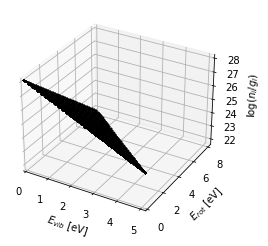

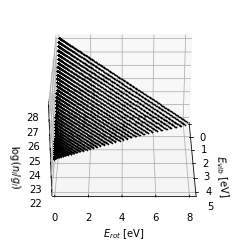

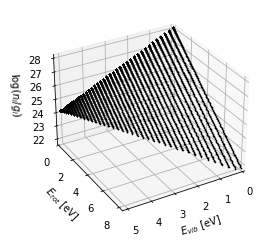

In [10]:
for i, axim in enumerate(tqdm([-60,0,60])):
    anim = get_animation(
        t_vec=t,
        n_sts=n_sts,
        frames=frames,
        axim=axim
    )

    # Save animation
    anim.save(f'{figs}/view_{i}.mp4', fps=frames/10, dpi=600)

    # Display animation
    HTML(anim.to_jshtml())

OLS surface fitting

In [11]:
# Construct X matrix
x = lev_dtb['EVib'], lev_dtb['ERot']
order = 3

X = []
poly_indices = []
for i in range(order+1):
    for j in range(order-i+1):
        X.append(x[0]**j * x[1]**i)
        poly_indices.append([j,i])
poly_indices = np.array(poly_indices)
X = np.stack(X, axis=1)

X_tr = np.transpose(X)
X_inv = np.linalg.inv(np.matmul(X_tr,X))

In [12]:
def get_ols_fitting(n_sts_ln):
    Y = np.matmul(X_tr, n_sts_ln.reshape(-1,1))
    w = np.matmul(X_inv, Y)
    return np.matmul(X, w).squeeze()

In [13]:
# Initialize lines for levels distribution
def init_lines(
    ax,
    axim=0.
):
    # Set up axes
    ax.set_xlabel(r'$E_{vib}$ [eV]')
    ax.set_ylabel(r'$E_{rot}$ [eV]')
    ax.set_zlabel(r'$\log(n_i/g_i)$')
    # Initialize lines.Line2D objects
    lines = [
        ax.plot3D([],[],[],c='k',**style)[0],
        ax.plot3D([],[],[],c='r',**style)[0]
    ]
    ax.view_init(elev=30, azim=axim)
    return ax, lines

# Create animation
def get_animation(
    t_vec,
    n_sts_ln,
    frames,
    axim=0.
):
    # Initialize a figure in which the graphs will be plotted
    fig = plt.figure()
    ax = fig.add_subplot(projection="3d")
    # Initialize levels distribution lines objects
    ax, lines = init_lines(ax, axim=axim)
    xlim = [np.amin(lev_dtb['EVib']), np.amax(lev_dtb['EVib'])]
    ylim = [np.amin(lev_dtb['ERot']), np.amax(lev_dtb['ERot'])]
    
    def animate(frame):
        idx = int(frame/frames*len(t_vec))
        # Plot distribution
        for l in lines:
            l.set_xdata(lev_dtb['EVib'])
            l.set_ydata(lev_dtb['ERot'])
        true = n_sts_ln[idx]
        pred = get_ols_fitting(n_sts_ln[idx])
        lines[0].set_3d_properties(true)
        lines[1].set_3d_properties(pred)
        # Rescale axis limits
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        zlim = [
            min(np.amin(true),np.amin(pred)),
            max(np.amax(true),np.amax(pred))
        ]
        ax.set_zlim(zlim)
        return lines
        
    # Get animation
    return FuncAnimation(
        fig,
        animate,
        frames=frames,
        blit=True
    )


  0%|          | 0/3 [00:00<?, ?it/s]

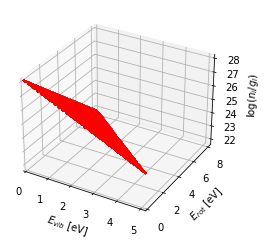

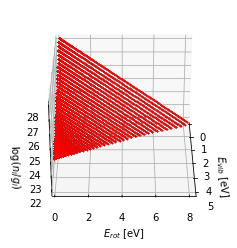

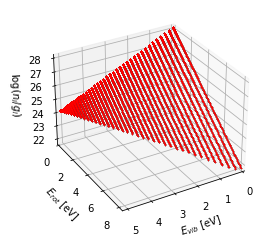

In [14]:
for i, axim in enumerate(tqdm([-60,0,60])):
    anim = get_animation(
        t_vec=t,
        n_sts_ln=n_sts_ln,
        frames=frames,
        axim=axim
    )

    # Save animation
    anim.save(f'{figs}/view_fit_{i}.mp4', fps=frames/10, dpi=600)

    # Display animation
    HTML(anim.to_jshtml())

Polynomial coefficients time evolution

In [15]:
frames = 100

w, t_vec= [], []
for frame in tqdm(range(frames)):
    idx = int(frame/frames*len(t))
    t_vec.append(t[idx])
    pred = get_ols_fitting(n_sts_ln[idx])
    Y = np.matmul(X_tr, n_sts_ln[idx].reshape(-1,1))
    w.append(np.matmul(X_inv, Y).T)

t_vec = np.concatenate(t_vec)
w = np.vstack(w)
poly_orders = np.sum(poly_indices, axis=1)

  0%|          | 0/100 [00:00<?, ?it/s]

In [16]:
for o in range(order+1):
    fig, ax = plt.subplots()
    ax.set_ylabel(r'Polynomial coefficients value')
    ax.set_xscale('log')
    ax.set_title(f'{o} order')
    plt.plot(t_vec, w[:,np.where(poly_orders == o)[0]])
    plt.savefig(f'{figs}/{o}_order_coeff.pdf', dpi=600)
    plt.close()